# Figure 2

Memory-guided visual search task (session 2 behavior). Supplementary panels are in `supp_figure1.ipynb` and `supp_figure2.ipynb`, which read `dataframes/search_data_all.csv` produced by this notebook.

In [1]:
import os.path as op
import os
os.environ.setdefault("OUTDATED_IGNORE", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg

from mgvs_release import config
from mgvs_release.bids import load_events
from mgvs_release.plotting import setup_style, push_to_back, save_fig
from mgvs_release.eyetracking import (
    ang_to_xy, ang_dist, parse_response_saccades, parse_fixation_saccades,
    usable_sample_qc, iti_fixation_precision, parse_calibration_qc,
)
from mgvs_release.stats import paired_ttest

In [2]:
setup_style()

In [3]:
bids_dir = config.BIDS_DIR
deriv_dir = config.DERIV_DIR
subjects = config.SUBJECTS
target_eccen = config.TARGET_ECCEN

save_dir = '../plots/'
dataframes_dir = '../dataframes/'

## Load behavioral data

In [4]:
behav = []

for s in subjects:
    df = load_events(bids_dir, s, task="search")
    df['subject'] = s
    behav.append(df)

behav = pd.concat(behav).reset_index(drop=True)

In [5]:
# Define control location
behav['cont_ang'] = behav['target_ang'] + -1 * (behav['comp_ang'] - behav['target_ang'])
behav['cont_ang'] %= 360
cont_x, cont_y = zip(*behav.apply(lambda x: ang_to_xy(x['cont_ang'], x['target_eccen']), axis=1).values)
behav['cont_x'] = cont_x
behav['cont_y'] = cont_y

## Search saccades

In [6]:
sacc = parse_response_saccades(deriv_dir, subjects, task="search", epoch=2)

In [7]:
data = behav.merge(sacc, on=['subject', 'run', 'trial'], how='outer')

In [8]:
data['sacc_targ_err'] = data.apply(
    lambda x: ang_dist(x['target_x'], x['target_y'], x['x_end'], x['y_end']), axis=1)
data['sacc_comp_err'] = data.apply(
    lambda x: ang_dist(x['comp_x'], x['comp_y'], x['x_end'], x['y_end']), axis=1)
data['sacc_cont_err'] = data.apply(
    lambda x: ang_dist(x['cont_x'], x['cont_y'], x['x_end'], x['y_end']), axis=1)
data['sacc_warp_err'] = data.apply(
    lambda x: ang_dist(x['warp_x'], x['warp_y'], x['x_end'], x['y_end']), axis=1)

In [9]:
err_thresh = 22.5
data['comp_resp'] = data['sacc_comp_err'] < err_thresh
data['targ_resp'] = data['sacc_targ_err'] < err_thresh
data['cont_resp'] = data['sacc_cont_err'] < err_thresh
data['warp_resp'] = data['sacc_warp_err'] < err_thresh

In [10]:
inbtwn = np.round(data['sacc_comp_err'] + data['sacc_targ_err']) == data['targ_comp_dist']
overshoot = np.logical_and(data['sacc_comp_err'] < data['sacc_targ_err'],
                           data['sacc_comp_err'] < 180 - data['targ_comp_dist'])

data['toward_comp'] = False
data.loc[inbtwn, 'toward_comp'] = True
data.loc[overshoot, 'toward_comp'] = True

data['toward_comp'] = data['toward_comp'].map({True: 1, False: -1})
data.loc[data['targ_comp_dist']==180, 'toward_comp'] = np.nan

In [11]:
data['targ_err_toward'] = data['sacc_targ_err'] * data['toward_comp']
data['norm_err_toward'] = data['targ_err_toward'] / data['targ_comp_dist']

In [12]:
data.to_csv(op.join(dataframes_dir, 'search_data_all.csv'), index=False)

## Reported in text: saccades per trial

In [13]:
sacc1 = data.query("sacc_num==1") #tot_sacc duplicated for every saccade, so select just the first one
print('median saccades/trial, across all runs and participants:', sacc1['tot_sacc'].median())

median saccades/trial, across all runs and participants: 3.0


In [14]:
# Fewer saccades for accurate trials than inaccurate trials
sacc1_median_by_resp = sacc1.groupby(['subject', 'warp_resp']).median(numeric_only=True).reset_index()
paired_ttest(sacc1_median_by_resp.query("warp_resp==True")['tot_sacc'],
             sacc1_median_by_resp.query("warp_resp==False")['tot_sacc'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-6.170963,31,two-sided,7.550864e-07,"[-0.87, -0.44]",0.941948,2.275e+04,0.999307


## Fig 2C: Search accuracy by condition (first saccade)

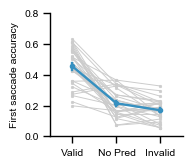

In [15]:
f, ax = plt.subplots(1, 1, figsize=(1.95, 1.7))

plot_data = data.query(
    "trial!=1 & sacc_first==True"
).groupby(['subject', 'target_validity']).mean(numeric_only=True).reset_index()

sns.pointplot(y='warp_resp', x='target_validity', hue='subject', errorbar=('ci', 0),
              hue_order=subjects, linewidth=.7, palette=['#cccccc'] * len(subjects),
              order=['valid', 'nopred', 'invalid'],
              zorder=-100, ax=ax,
              data=plot_data)
push_to_back(ax)

sns.pointplot(y='warp_resp', x='target_validity', errorbar='se',
              color='#3690c0',
              order=['valid', 'nopred', 'invalid'],
              linewidth=1.7, ms=2.7,
              ax=ax,
              data=plot_data)

ax.set(ylabel='First saccade accuracy', xlabel='',
       ylim=[0, .8], xticks=range(3), xticklabels=['Valid', 'No Pred', 'Invalid'])
ax.legend_ = None
sns.despine()
f.tight_layout()
save_fig(f, op.join(save_dir, 'fig2c'))

In [16]:
cond_subj_mean = data.query(
    "trial!=1 & sacc_first==True"
).groupby(['subject', 'target_validity']).mean(numeric_only=True).reset_index()
cond_subj_mean.groupby(['target_validity'])['warp_resp'].mean()

target_validity
invalid    0.169454
nopred     0.215008
valid      0.454258
Name: warp_resp, dtype: float64

In [17]:
# Effect of target validity on accuracy
pg.rm_anova(data=cond_subj_mean, dv='warp_resp', within=['target_validity'], subject='subject', effsize='np2')

,Source,ddof1,ddof2,F,p-unc,p-GG-corr,np2,eps,sphericity,W-spher,p-spher
0,target_validity,2,62,78.726932,9.605107e-18,1.503637e-12,0.71748,0.663496,False,0.492831,0.000025


In [18]:
# Valid condition has greater accuracy than no prediction condition
paired_ttest(cond_subj_mean.query("target_validity=='valid'")['warp_resp'],
             cond_subj_mean.query("target_validity=='nopred'")['warp_resp'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,8.716902,31,two-sided,7.646697e-10,"[0.18, 0.3]",2.299391,1.466e+07,1.0


In [19]:
# Valid condition has greater accuracy than invalid condition
paired_ttest(cond_subj_mean.query("target_validity=='valid'")['warp_resp'],
             cond_subj_mean.query("target_validity=='invalid'")['warp_resp'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,9.739073,31,two-sided,6.002965e-11,"[0.23, 0.34]",2.906827,1.635e+08,1.0


In [20]:
# Invalid condition has lower accuracy than no prediction condition
paired_ttest(cond_subj_mean.query("target_validity=='invalid'")['warp_resp'],
             cond_subj_mean.query("target_validity=='nopred'")['warp_resp'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-3.441109,31,two-sided,0.001677,"[-0.07, -0.02]",0.599671,20.635,0.907492


## Fig 2D: Interference in valid trials (distribution, first saccade)

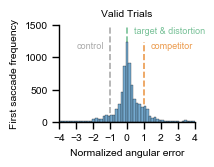

In [21]:
f, ax = plt.subplots(1, 1, figsize=(2.1, 1.7))
plot_data = data.query("trial!=1 & sacc_first==True & target_validity=='valid' & targ_comp_dist!=180")
g = sns.histplot(x='norm_err_toward', alpha=1, ax=ax,
                color='#74a9cf', binwidth=.15,
                data=plot_data)
ax.axvline(x=0, c="#3fa76cb3", ls="--", zorder=-100)
ax.axvline(x=1, c="#e37103b3", ls="--", zorder=-100)
ax.axvline(x=-1, c="#aaaaaa", ls="--", zorder=-100)

ax.set(xlim=[-4, 4], xticks=np.arange(-4, 5), ylim=[0, 1400])
ax.text(0.4, 1360, 'target & distortion', backgroundcolor='1', c='#3fa76cb3', fontsize=6.5)
ax.text(1.4, 1130, 'competitor', c="#e37103b3", fontsize=6.5)
ax.text(-2.95, 1130, 'control', c="#aaaaaa", fontsize=6.5)
ax.set(xlabel='Normalized angular error', ylabel='First saccade frequency',
      title='Valid Trials', ylim=[0, 1500])
sns.despine()
f.tight_layout()
save_fig(f, op.join(save_dir, 'fig2d'))

## Fig 2E: Interference in valid trials (competitor vs control, first saccade)

In [22]:
# Control location cannot be defined for 180 degree pairs
subj_mean_no180 = data.query(
    "trial!=1 & sacc_first==True & target_validity=='valid' & targ_comp_dist!=180"
).groupby(['subject']).mean(numeric_only=True).reset_index()

In [23]:
# More competitor than control saccades
paired_ttest(subj_mean_no180['comp_resp'], subj_mean_no180['cont_resp'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,7.591057,31,two-sided,1.473846e-08,"[0.06, 0.1]",2.24551,9.011e+05,1.0


In [24]:
comp_cont_df = subj_mean_no180.melt(id_vars=['subject',],
                                       value_vars=['comp_resp', 'cont_resp'],
                                       var_name='resp_cat', value_name='prob')

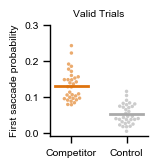

In [25]:
pal = ['#de730e', '#aaaaaa']
f, ax = plt.subplots(1, 1, figsize=(1.6, 1.7))

sns.swarmplot(x='resp_cat', y='prob', hue='resp_cat', palette=pal, size=2.5, alpha=.6,
                   legend=False, data=comp_cont_df, ax=ax)

comp_mean = subj_mean_no180['comp_resp'].mean()
control_mean = subj_mean_no180['cont_resp'].mean()
ax.plot([-.3, .3], [comp_mean, comp_mean], c=pal[0], lw=2)
ax.plot([1-.3, 1+.3], [control_mean, control_mean], c=pal[1], lw=2)

ax.legend_ = None
ax.set(ylim=[-.01,.3], xlabel='', ylabel='First saccade probability', title='Valid Trials',
       xticks=range(2), xticklabels=['Competitor', 'Control'])
plt.gcf().tight_layout()
sns.despine()

save_fig(f, op.join(save_dir, 'fig2e'))

## Fig 2F: Effect of target-competitor distance (first saccade)

In [26]:
# Above analysis separately by target-competitor distance
subj_mean_dist_no180 = data.query(
    "trial!=1 & sacc_first==True & target_validity=='valid' & targ_comp_dist!=180"
).groupby(['subject', 'targ_comp_dist']).mean(numeric_only=True).reset_index()
comp_cont_dist_df = subj_mean_dist_no180.melt(id_vars=['subject', 'targ_comp_dist'],
                                       value_vars=['comp_resp', 'cont_resp'],
                                       var_name='resp_cat', value_name='prob')

In [27]:
# Interaction between competitor/control saccades and target-competitor distance
pg.rm_anova(data=comp_cont_dist_df, dv='prob', subject='subject', effsize='np2',
            within=['resp_cat', 'targ_comp_dist'])

,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,np2,eps
0,resp_cat,0.309035,1,31,0.309035,59.532500,1.053906e-08,1.053906e-08,0.657582,1.000000
1,targ_comp_dist,0.364589,2,62,0.182295,77.374974,1.410631e-17,8.289190e-16,0.713956,0.884004
2,resp_cat * targ_comp_dist,0.030009,2,62,0.015004,5.930929,4.396583e-03,6.899527e-03,0.160595,0.854375


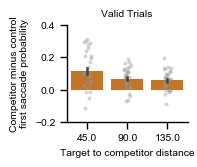

In [28]:
subj_mean_dist_no180['comp_cont_resp_diff'] = (subj_mean_dist_no180['comp_resp'] -
                                                subj_mean_dist_no180['cont_resp'])

pal = ['#de730e', '#aaaaaa']
f, ax = plt.subplots(1, 1, figsize=(2, 1.7))

sns.barplot(x='targ_comp_dist', y='comp_cont_resp_diff',
           color=pal[0], errorbar='se', err_kws={'zorder': 3},
            data=subj_mean_dist_no180, ax=ax)

sns.stripplot(x='targ_comp_dist', y='comp_cont_resp_diff',
            color='.6', zorder=2,
            size=2.5, alpha=.4, edgecolor=".5", linewidth=.2,
            data=subj_mean_dist_no180, ax=ax)


ax.legend_ = None
ax.set(ylim=[-.2, .4], ylabel='Competitor minus control\nfirst saccade probability', title='Valid Trials',
       xlabel='Target to competitor distance')
sns.despine()
plt.gcf().tight_layout()

save_fig(f, op.join(save_dir, 'fig2f'))

## Reported in text: correct responses are biased toward the competitor location

In [29]:
mean_corr_toward = data.query(
    "trial!=1 & sacc_first==True & warp_resp==True"
    "& target_validity=='valid' & targ_comp_dist!=180"
).groupby(['subject']).mean(numeric_only=True)['targ_err_toward']
pg.ttest(mean_corr_toward, 0)

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,2.43257,31,two-sided,0.020959,"[0.13, 1.49]",0.430022,2.368,0.654228


## Reported in text: correlation between session 1 (learning) and session 2 (search) performance

In [30]:
last_test_mean = pd.read_csv(op.join(dataframes_dir, 'learn_subj_firstlast.csv')).query("run_cat=='last'")

In [31]:
all_perf = cond_subj_mean.merge(last_test_mean[['subject', 'targ_resp', 'comp_resp']],
                                 on=['subject'], suffixes=('', '_test'))

In [32]:
# Across-subject correlation between session 1 and session 2 target responses
pg.corr(all_perf.query("target_validity=='valid'")['targ_resp_test'],
        all_perf.query("target_validity=='valid'")['targ_resp'])

,n,r,CI95%,p-val,BF10,power
pearson,32,0.556558,"[0.26, 0.76]",0.000939,41.162,0.928568


In [33]:
# Across-subject correlation between session 1 and session 2 competitor responses
pg.corr(all_perf.query("target_validity=='valid'")['comp_resp_test'],
        all_perf.query("target_validity=='valid'")['comp_resp'])

,n,r,CI95%,p-val,BF10,power
pearson,32,0.395294,"[0.05, 0.65]",0.02514,2.423,0.62611


## Identify fixation breaks during ITI

In [34]:
fix_break = parse_fixation_saccades(deriv_dir, subjects, task="search", epoch=1) #Pre-trial ITI fixation epoch

In [35]:
# The eyetracking .mat file labels each ITI fixation window with the trial it precedes,
# but search_design's 'iti' column lives on the trial it follows. Shift behavioral trial
# numbers by +1 so each ITI lines up with the fixation window it actually corresponds to.
behav_roll = behav.copy()
behav_roll['trial'] = behav_roll['trial']+1
fix_break = fix_break.merge(behav_roll[['subject', 'run', 'trial', 'iti', 'next_targ_comp_dist']],
                            on=['subject', 'run', 'trial'], how='outer')

In [36]:
# Cap the analyzed fixation window to a fixed length -- the shortest of the
# 3 jittered trial durations' ITIs (6s trial - 1.25s stim_dur = 4.75s)
MIN_ITI_SEC = 4.75
fix_break['iti_cutoff'] = MIN_ITI_SEC - fix_break['iti']
fix_break['sacc_include'] = fix_break['sacc_onset'] < fix_break['iti_cutoff']

In [37]:
# A saccade counts as a fixation break if it starts at fixation (within
# FIX_START_RADIUS deg of center and lands at least FIX_BREAK_MIN_DIST deg away
# -- about halfway to the 3.3 deg target eccentricity
FIX_START_RADIUS = .5
FIX_BREAK_MIN_DIST = 1.75

fix_break_trials = fix_break.query(
    "trial!=1 & x_start_abs<@FIX_START_RADIUS & y_start_abs<@FIX_START_RADIUS & "
    "end_dist>@FIX_BREAK_MIN_DIST & sacc_include==True"
).reset_index(drop=True)
fix_break_summary = fix_break_trials.groupby(['subject', 'run', 'trial'])['sacc_include'].nunique().reset_index()
fix_break_summary.to_csv(op.join(dataframes_dir, "fix_break_trials.csv"), index=False)

## Reported in text: Eyetracking data quality

Median trials/run with a fixation break during the ITI

In [38]:
fix_break.query(
    "trial!=1 & x_start_abs<@FIX_START_RADIUS & y_start_abs<@FIX_START_RADIUS & "
    "end_dist>@FIX_BREAK_MIN_DIST & sacc_include==True"
).groupby(["subject", "run"])["trial"].nunique().median()

3.5

Spatial precision during ITI fixation

In [39]:
precision_subj = iti_fixation_precision(deriv_dir, subjects)
print(precision_subj["precision"].mean())
print(precision_subj["precision"].std())

0.46087210434425274
0.18082926658246293


Calibration error, parsed from Eyelink .asc message logs

In [40]:
summary = parse_calibration_qc(bids_dir, subjects)
print(summary['pct_cal_performed'].mean())
print(summary['pct_cal_performed'].min())
print(summary['pct_cal_performed'].max())
print(summary['mean_cal_precision'].mean())
print(summary['sd_cal_precision'].mean())

42.96875
12.5
100.0
0.46762371351766513
0.2667704960273484


Usable samples during search

In [41]:
qc_summary = usable_sample_qc(deriv_dir, subjects)
qc_summary.query("epoch==2")[["mean", "std"]]  # Search period epoch

,mean,std
epoch,,
2,88.589423,6.105906
